## Task 1: Data Loading (5 Marks)
Load the diabetes dataset and display the first few rows along with the shape.

In [ ]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [2]:
# Load the dataset
df = pd.read_csv('diabetes.csv')
display(df.head())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Task 2: Data Preprocessing (10 Marks)
Perform and document at least 5 distinct preprocessing steps.

In [ ]:
display(df.dtypes)
display(df.describe())

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [4]:
col_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

df[col_zeros] = df[col_zeros].replace(0, np.nan)
df[col_zeros] = df[col_zeros].fillna(df[col_zeros].median())

df_clean = df.copy()
display(df_clean.head())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


In [5]:
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    return len(outliers), lower_bound, upper_bound

for col in df_clean.columns[:-1]:
    outlier_count, lower, upper = detect_outliers_iqr(df_clean, col)
    print(f"{col}: {outlier_count} outliers")

Pregnancies: 4 outliers
Glucose: 0 outliers
BloodPressure: 14 outliers
SkinThickness: 87 outliers
Insulin: 346 outliers
BMI: 8 outliers
DiabetesPedigreeFunction: 29 outliers
Age: 9 outliers


In [6]:
def categorize_bmi(bmi):
    if bmi < 18.5:
        return 0
    elif bmi < 25:
        return 1
    elif bmi < 30:
        return 2
    else:
        return 3

df_clean['BMI_Category'] = df_clean['BMI'].apply(categorize_bmi)

def categorize_age(age):
    if age < 30:
        return 0
    elif age < 50:
        return 1
    else:
        return 2

df_clean['Age_Group'] = df_clean['Age'].apply(categorize_age)

df_clean['Glucose_Insulin_Ratio'] = df_clean['Glucose'] / (df_clean['Insulin'] + 1)

print(df_clean.shape)

(768, 12)


In [7]:
print(df_clean['Outcome'].value_counts())
print(df_clean['Outcome'].value_counts(normalize=True) * 100)

Outcome
0    500
1    268
Name: count, dtype: int64
Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64


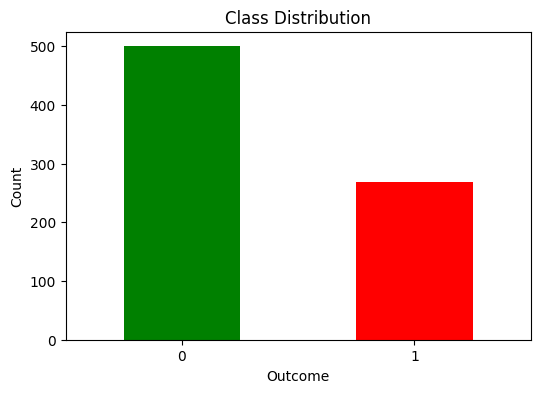

In [8]:
plt.figure(figsize=(6, 4))
df_clean['Outcome'].value_counts().plot(kind='bar', color=['green', 'red'])
plt.title('Class Distribution')
plt.xlabel('Outcome')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

In [9]:
X = df_clean.drop('Outcome', axis=1)
y = df_clean['Outcome']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set: {X_train.shape[0]}")
print(f"Testing set: {X_test.shape[0]}")

Training set: 614
Testing set: 154


## Task 3: Pipeline Creation (10 Marks)
Construct a standard Machine Learning pipeline that integrates preprocessing and the model.

In [10]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(random_state=42))
])

print(pipeline)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', RandomForestClassifier(random_state=42))])


## Task 4: Primary Model Selection (5 Marks)

### Why Random Forest?

1. It can handle non-linear data well
2. It is not affected much by outliers
3. It gives feature importance which helps understand the data
4. It works well with imbalanced datasets
5. It reduces overfitting by using multiple trees
6. It gives good accuracy for classification problems

## Task 5: Model Training (10 Marks)
Train the selected model using the training portion of the dataset.

In [11]:
pipeline.fit(X_train, y_train)

train_predictions = pipeline.predict(X_train)
train_accuracy = accuracy_score(y_train, train_predictions)
print(f"Training Accuracy: {train_accuracy:.4f}")

Training Accuracy: 1.0000


## Task 6: Cross-Validation (10 Marks)
Apply Cross-Validation to assess robustness and report the average score with standard deviation.

In [12]:
cv_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(random_state=42))
])

cv_scores = cross_val_score(cv_pipeline, X_train, y_train, cv=5, scoring='accuracy')

for i, score in enumerate(cv_scores, 1):
    print(f"Fold {i}: {score:.4f}")

print(f"Average: {cv_scores.mean():.4f}")
print(f"Std Dev: {cv_scores.std():.4f}")

Fold 1: 0.7398
Fold 2: 0.7561
Fold 3: 0.7480
Fold 4: 0.7886
Fold 5: 0.7623
Average: 0.7590
Std Dev: 0.0166


## Task 7: Hyperparameter Tuning (10 Marks)
Optimize your model using search methods displaying both the parameters tested and the best results found.

In [13]:
param_grid = {
    'classifier__n_estimators': [50, 100, 150],
    'classifier__max_depth': [5, 10, 15, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

grid_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(random_state=42))
])

grid_search = GridSearchCV(grid_pipeline, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train)

print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best Score: {grid_search.best_score_:.4f}")

Best Parameters: {'classifier__max_depth': 5, 'classifier__min_samples_leaf': 4, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 150}
Best Score: 0.7769


## Task 8: Best Model Selection (10 Marks)
Select the final best-performing model based on the hyperparameter tuning results.

In [14]:
best_model = grid_search.best_estimator_
print(best_model)

results_df = pd.DataFrame(grid_search.cv_results_)
results_df = results_df.sort_values('rank_test_score')

print("\nTop 5 combinations:")
for i in range(5):
    row = results_df.iloc[i]
    print(f"Rank {int(row['rank_test_score'])}: {row['mean_test_score']:.4f}")

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 RandomForestClassifier(max_depth=5, min_samples_leaf=4,
                                        min_samples_split=10, n_estimators=150,
                                        random_state=42))])

Top 5 combinations:
Rank 1: 0.7769
Rank 2: 0.7769
Rank 3: 0.7769
Rank 4: 0.7752
Rank 5: 0.7737


## Task 9: Model Performance Evaluation (10 Marks)
Evaluate the model on the test set and print comprehensive metrics suitable for the problem type.

Accuracy: 0.7208
Precision: 0.6279
Recall: 0.5000
F1 Score: 0.5567
              precision    recall  f1-score   support

           0       0.76      0.84      0.80       100
           1       0.63      0.50      0.56        54

    accuracy                           0.72       154
   macro avg       0.69      0.67      0.68       154
weighted avg       0.71      0.72      0.71       154



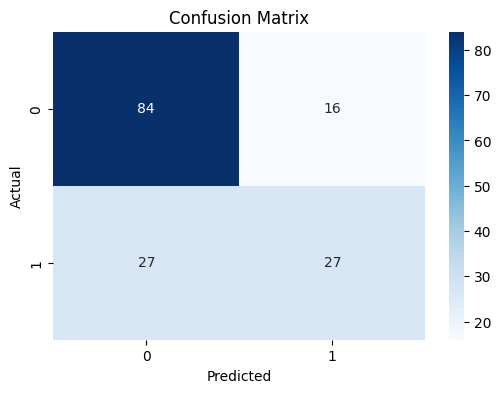

In [15]:
y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

                     Feature  Importance
1                    Glucose    0.359434
5                        BMI    0.132840
7                        Age    0.102797
4                    Insulin    0.072858
6   DiabetesPedigreeFunction    0.066743
8               BMI_Category    0.058351
10     Glucose_Insulin_Ratio    0.056050
0                Pregnancies    0.046206
9                  Age_Group    0.039869
3              SkinThickness    0.039578
2              BloodPressure    0.025275


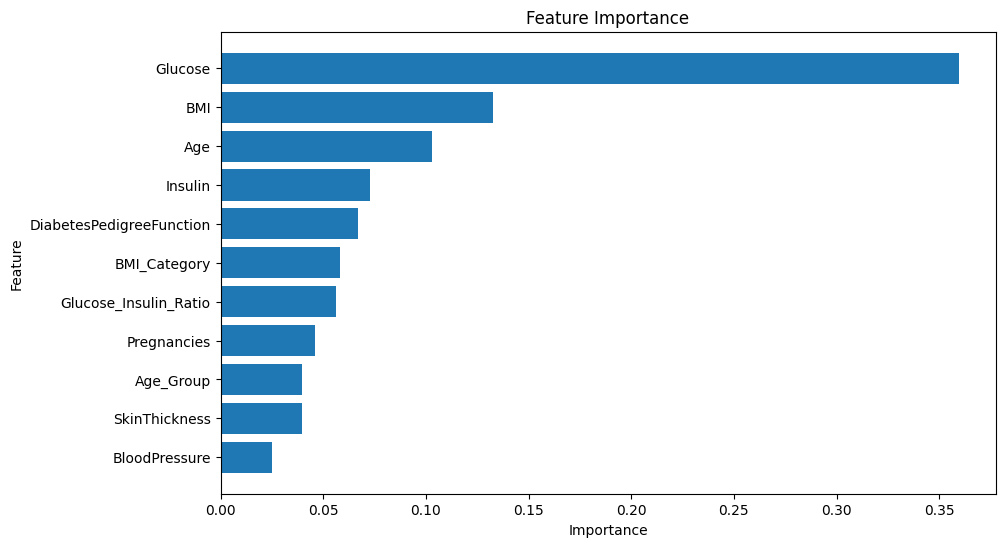

In [16]:
feature_importance = best_model.named_steps['classifier'].feature_importances_
feature_names = X.columns

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importance
}).sort_values('Importance', ascending=False)

print(importance_df)

plt.figure(figsize=(10, 6))
plt.barh(importance_df['Feature'], importance_df['Importance'])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Feature Importance')
plt.gca().invert_yaxis()
plt.show()

In [17]:
import joblib
joblib.dump(best_model, 'diabetes_model.pkl')
print("Model saved")

Model saved
